## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

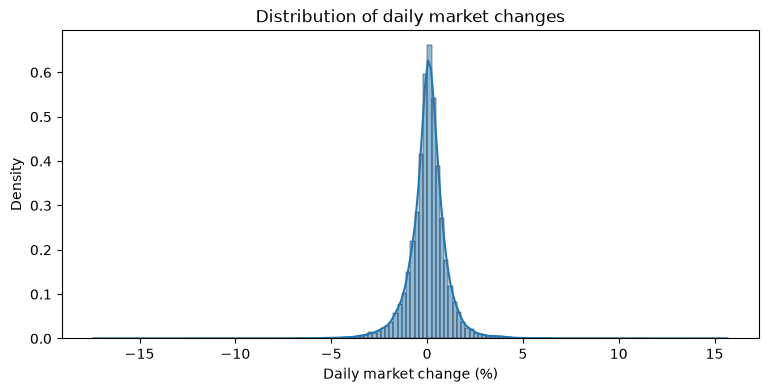

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

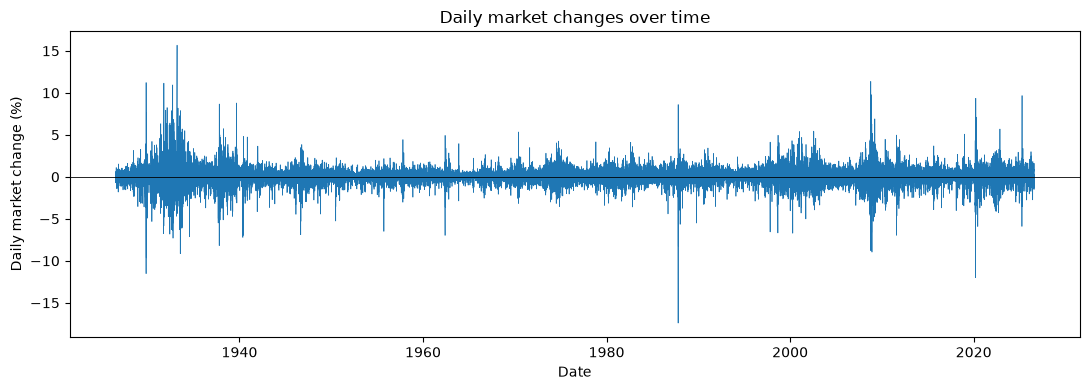

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Part One: Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [4]:
# make a categorical column "direction_t" 
direction_categories = ['Down / Flat', 'Up']

df['direction_t'] = pd.Categorical(
    np.where(df['market_return_pct'] > 0, 'Up', 'Down / Flat'),
    categories=direction_categories,
    ordered=True
)

In [5]:
# make a categorical column "direction_tp1" for the next trading day
df['direction_tp1'] = df['direction_t'].shift(-1)

In [6]:
df[['direction_t', 'direction_tp1']]

,direction_t,direction_tp1
0,Up,Up
1,Up,Up
2,Up,Up
3,Up,Up
4,Up,Down / Flat
...,...,...
26291,Up,Up
26292,Up,Down / Flat
26293,Down / Flat,Up
26294,Up,Up


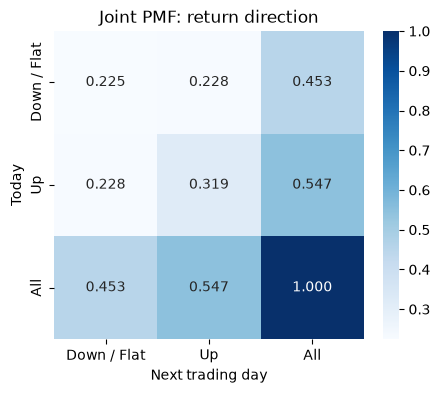

In [7]:
# Plot the joint PMF
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df['direction_t'], df['direction_tp1'], normalize = True, margins = True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

In [8]:
# Plot the conditional PMF
pd.crosstab(df['direction_t'], df['direction_tp1'], normalize='index')

direction_tp1,Down / Flat,Up
direction_t,,
Down / Flat,0.496221,0.503779
Up,0.416974,0.583026


<div class='alert alert-info'><b>Answer the following:</b>

- Are up transitions more or less common than down transitions?
    * Up transitions are more common than down transitions. The probability it is up tomorrow given down today is 0.504. Joint probability of up day today/tomorrow is higher than down. 
- Are you more likely to transition to an Up day from a Down or Up day?
    * More common to transition from an up day to another up day then from a down day to an up day. Per the conditional probability, P(up tomorrow | up today) is 0.583, while P(up tomorrow | down today) = 0.504. Practically, the stock market goes up in bull markets, more of a coin flip in bear behavior markets.

</div>

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- Subtract the marginal PMF of tomorrow's state from each row of the conditional PMF, and plot the result as a heatmap. If tomorrow's state were independent of today's, every row of the conditional PMF would equal this marginal. Which transitions are more likely than independence predicts, and which are less likely? Does knowing today's state change the forecast for tomorrow?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [9]:
return_categories = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['return_bin'] = pd.cut(df['market_return_pct'], bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf], labels = return_categories)


In [10]:
df['return_bin'].value_counts()

return_bin
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

In [11]:
#make y_t and y_tp1 columns for the return bins
df['y_t'] = df['return_bin']
df['y_tp1'] = df['return_bin'].shift(-1)

<div class='alert alert-info'><b>Answer the following:</b>

- How many days fall into each of the five bins?  (use value_counts)
  * Printed above
- Which are the most or least common?
  * small gain is the most common, followed by small loss.
  * Large gain/large loss are the least common.
  
  </div>

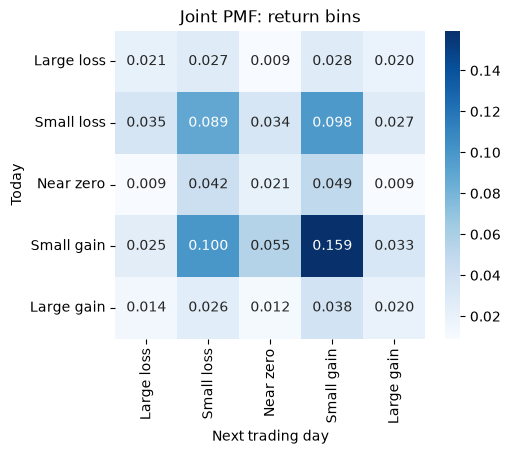

In [12]:
#joint PMF with marginals
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df['y_t'], df['y_tp1'], normalize = True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return bins')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Which transitions are most likely to occur? 
* small gain -> small gain, small gain -> small loss, small loss -> small loss, small loss -> small gain. These are the most common values in the dataframe so this makes sense. On the average day, the market does not fluctuate up or down very much.

</div>

In [13]:
#conditional PMF 
pd.crosstab(df['y_t'], df['y_tp1'], normalize = 'index')


y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


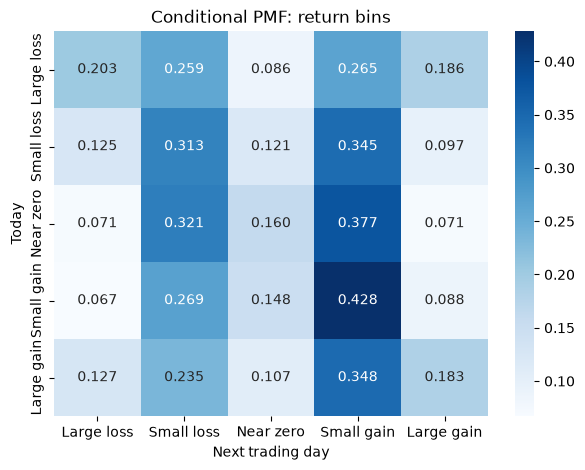

In [14]:
#joint PMF with marginals
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(pd.crosstab(df['y_t'], df['y_tp1'], normalize="index"),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Conditional PMF: return bins')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- For each current state, which two future states are the most likely? 
    * Small gain tomorrow and small loss tomorrow are always the most likely future states given any current state.
- Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? 
    * Could be a very coarse version of a uniform 0.2 probability distribution, But I would argue that small gain/loss are more than 0.2 and large gain/loss and near zero are less than 0.2. 
- Is it relatively easy or difficult to predict the next state?
    * Information from the state of the market today does not give much information on the market tomorrow, because while the columns don't have exactly the same probability within the column (which would show they are independent), they follow a pattern and are similiar.
</div>

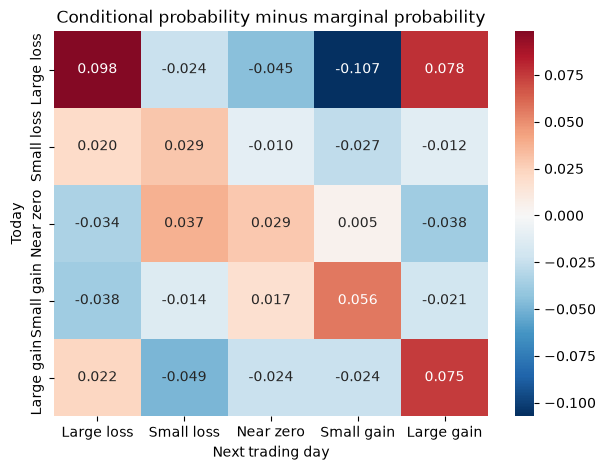

In [15]:
# marginal PMF of tomorrow's state: sum the joint PMF (without margins) down each column
next_state_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True).sum(axis=0)

conditional = pd.crosstab(df['y_t'], df['y_tp1'], normalize="index")
# subtract it from each row of the conditional PMF and plot as a heatmap
# hint: use .sub(next_state_pmf, axis='columns'), and a diverging colormap such as cmap='RdBu_r' with center=0
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(conditional.sub(next_state_pmf, axis='columns'),
            annot=True, fmt='.3f', center=0, cmap='RdBu_r', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today',
       title='Conditional probability minus marginal probability')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Which transitions are more likely than independence predicts, and which are less likely?
    * Independence would predict 0 for all values.
    * Large loss -> large loss, large loss -> large gain, large gain -> large gain, and everything along the diagonal are slightly more likely than independence would predict. large loss -> small gain, large gain -> small loss, and most everything off the diagonal are somewhat less likely than independence would predict. Even though there is some directional strength, these values are relatively small and all others are very close to 0.

- Does knowing today's state change the forecast for tomorrow?
    * Slightly. Since not all cells are 0, this means that the conditional shifts the forecast. It seems that days of similiar market moves happen after each other.
- How is this comparison different from comparing each row to a uniform PMF with probability .2?
    * This is not the same because it is not a table of probabilities, but instead the differences that show how the conditional informs the forecast.
</div>

In [16]:
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)
# use groupby and describe/mean to get the conditional expectation of the next day's return given today's return bin y_t

df.groupby('y_t')['market_return_pct_tp1'].describe()

C:\Users\jacob\AppData\Local\Temp\ipykernel_25340\2019937621.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('y_t')['market_return_pct_tp1'].describe()


,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


<div class='alert alert-info'><b>Answer the following:</b>

- Given the current state, what are the expected percent returns for tomorrow? 
    * This is the mean of each column (above). So given large loss today, expected percent returns tomorrow are close to zero slightly negative.
- How do the min and max values for tomorrow vary across states? 
    * mins and maxes become less extreme as the y_t move from large loss/gain toward near zero.
- Which states have the highest standard deviation for tomorrow's percent returns? 
    * Large loss/gain have the largest standard deviations for tomorrows percent returns. The extremes being largest here from the previous question are consistent with this.
- Describe any patterns in the volatility you notice.
    * If there is a large gain or loss today, market is very volatile in the next day. Less volatile for small losses or gains. This makes sense based on what I know about the stock market, that it is very volatile in both directions when there are shocks in the market.
</div>


### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [17]:
#cut into 21 equal-sized bins and make y_t and y_tp1 columns for the return bins
bins = 21
labels = [f"Q{i+1}" for i in range(bins)]

df['y_t'] = pd.qcut(df['market_return_pct'], q=bins, labels=labels)
df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts(sort=False).rename('Trading days').to_frame().T

y_t,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19,Q20,Q21
Trading days,1255,1253,1286,1280,1230,1226,1371,1206,1198,1331,...,1223,1294,1223,1310,1193,1211,1283,1225,1250,1238


In [18]:
#joint PMF with marginals for the 21 quantile bins + plot as heatmap
quantile_joint = pd.crosstab(
    df['y_t'], df['y_tp1'], normalize=True, margins = False
)

<Axes: xlabel='y_tp1', ylabel='y_t'>

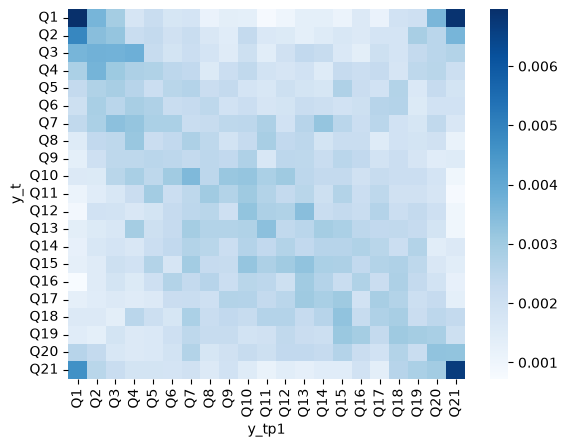

In [19]:
sns.heatmap(quantile_joint, cmap = 'Blues')

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?
* The trend of higher values along the diagonal continues. This suggests that the quantile of one day occurs more often with a similiar quantile the next day then it would under independence.

</div>

<Axes: xlabel='y_tp1', ylabel='y_t'>

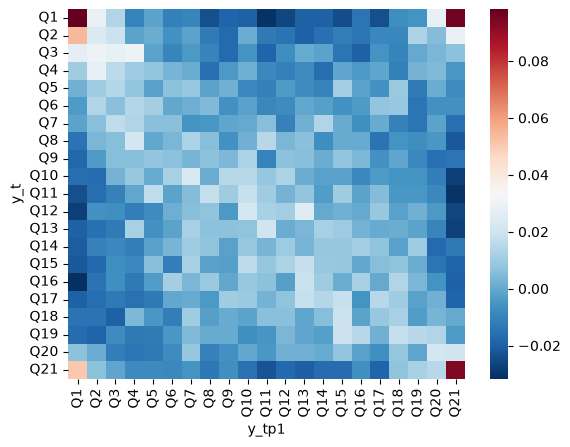

In [20]:
# compute and plot the conditional
# REVISION SAID TO SUBTRACT 1/21 TO PLOT
quantile_conditional = pd.crosstab(
    df['y_t'], df['y_tp1'], normalize='index', margins = False
)

sns.heatmap(quantile_conditional - 1/21, cmap = 'RdBu_r')

<Axes: xlabel='y_tp1', ylabel='y_t'>

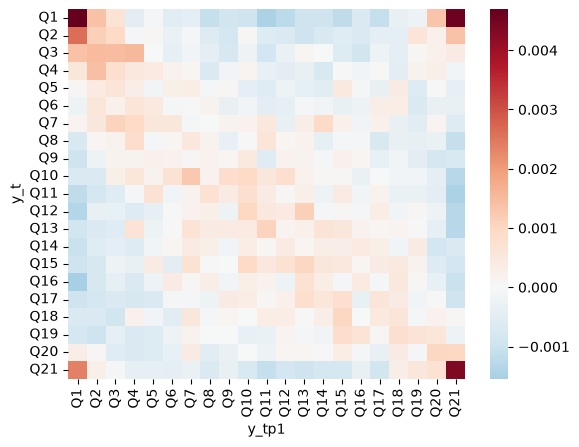

In [21]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.
sns.heatmap(quantile_joint - 1/21**2, cmap='RdBu_r', center=0)

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

* To orient ourselves, in the joint pmf the uniform would be (1/21)*(1/21) = P(today)*P(tomorrow) assuming independence and uniform distribution. For the conditional PMF under the same uniform distribution, we expect ech row to have 1/21 in every box because every row adds to one: P(Tomorrow|Today) = 1/21. We subtract each of these probabilities from their respective plot to see actual deviations from what would be expected if everything followed a uniform distribution.
* Because there are some slightly positive values near the diagonal, this suggests that quantiles tend to stay near each other from today to tomorrow. Practically this means that a Q11 quantile trading day on one day means that the next day is more likely to have a trading day near to Q11.
* Another big insight is the corners, that have high values across the plots. This reinforces our belief that in periods of market volatility, there are huge swings from low -> low, low -> high, high -> low, high -> high.

</div>

In [22]:
# compute the next day's min, mean, and max conditional on each bin
quantile_stats = df.groupby('y_t')['market_return_pct_tp1'].describe().reset_index()
quantile_stats[['y_t', 'min', 'mean', 'max']]

C:\Users\jacob\AppData\Local\Temp\ipykernel_25340\2293577587.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  quantile_stats = df.groupby('y_t')['market_return_pct_tp1'].describe().reset_index()


,y_t,min,mean,max
0,Q1,-17.41,-0.013713,11.22
1,Q2,-7.36,-0.076712,6.36
2,Q3,-8.79,-0.097084,11.36
3,Q4,-8.28,-0.058594,6.16
4,Q5,-6.89,-0.024211,4.56
5,Q6,-11.23,-0.022692,6.37
6,Q7,-3.94,-0.030241,7.37
7,Q8,-3.40,-0.014303,4.76
8,Q9,-6.00,0.025860,5.49
9,Q10,-8.19,-0.012998,3.60


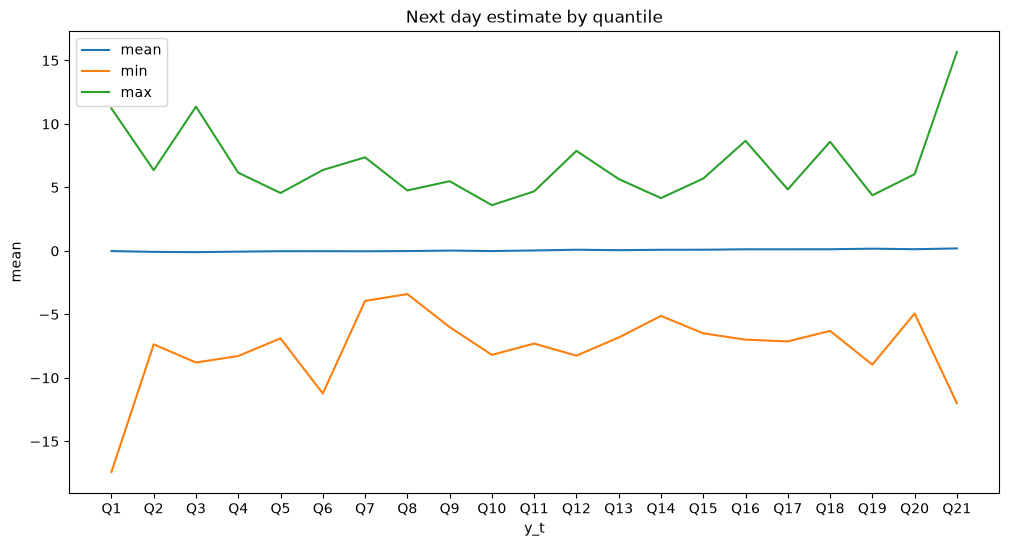

In [23]:
#plot as lines on a graph against the bins
plt.figure(figsize=(12, 6))

sns.lineplot(quantile_stats, x = 'y_t', y = 'mean', label = 'mean')
sns.lineplot(quantile_stats, x = 'y_t', y = 'min', label = 'min')
sns.lineplot(quantile_stats, x = 'y_t', y = 'max', label = 'max')
plt.title('Next day estimate by quantile')

plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?
* Slightly smaller mins and maxes near the middle quantiles, with higher mins and maxes near the ends. While this is a pattern, it is not useful for actually predicting new values. Again, we see the extremes to be more volatile.

</div>

In [24]:
quantile_stats

,y_t,count,mean,std,min,25%,50%,75%,max
0,Q1,1255.0,-0.013713,2.140465,-17.41,-0.9150,-0.02,0.9000,11.22
1,Q2,1253.0,-0.076712,1.285882,-7.36,-0.7400,-0.02,0.6000,6.36
2,Q3,1286.0,-0.097084,1.227976,-8.79,-0.7100,-0.03,0.4700,11.36
3,Q4,1280.0,-0.058594,1.049607,-8.28,-0.5800,0.00,0.4925,6.16
4,Q5,1230.0,-0.024211,0.989470,-6.89,-0.4675,0.02,0.4675,4.56
5,Q6,1226.0,-0.022692,1.024761,-11.23,-0.4975,0.02,0.5000,6.37
6,Q7,1371.0,-0.030241,0.930389,-3.94,-0.4950,0.03,0.4100,7.37
7,Q8,1206.0,-0.014303,0.835663,-3.40,-0.4200,0.03,0.4100,4.76
8,Q9,1198.0,0.025860,0.853220,-6.00,-0.3900,0.03,0.4400,5.49
9,Q10,1331.0,-0.012998,0.811559,-8.19,-0.3450,0.02,0.3750,3.60


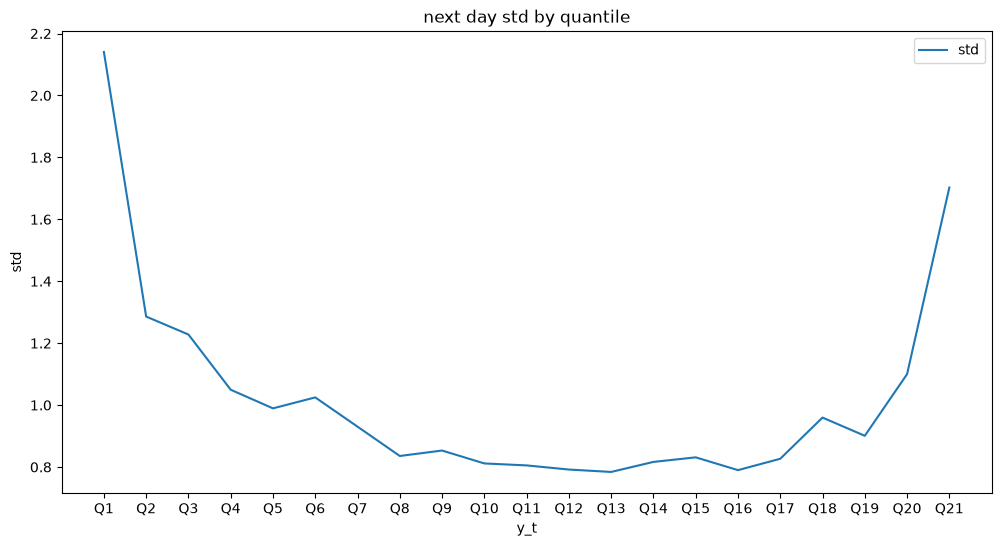

In [25]:
#compute the next day's standard deviation, and plot it as a line graph against the bins.
plt.figure(figsize=(12, 6))
sns.lineplot(quantile_stats, x = 'y_t', y = 'std', label = 'std')
plt.title('next day std by quantile')
plt.show()


<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?
* Standard deviation is higher at the high and low quantiles, which signals high market volatility when it is already having more swings. This is consistent with more extreme mins/maxes in the previous graph.

</div>

<div class='alert alert-info'><b>Answer the following:</b>

How easy is it to predict the market?

* If it were possible to predict the market, people would already be doing it like crazy. Based on this analysis, knowing what the market does on any given day gives little insight into what it will do tomorrow. From the activity, there are a couple useful takeaways:
    * The market is really hard to predict (already addressed)
    * The market tends to go up over time, so it's a 'safe bet' to assume that if the market goes up one day, that it will go up the next, at least on average.
    * During periods of high market swings on one day, the move of the market the next day typicically has high volatility. This is shown by the std plots with high stds on extreme quantile days and also by the high probabilities in the corners that show massive swings one one day are often followed by more massive swings on the next day. I like this because it reveals some of the behavior of bull (stable, consistently moving up) versus bear markets (back and forth) that I have learned about from investing.
</div>